In [41]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Specify each path

In [42]:
dataset = 'model/keypoint_classifier/keypoint.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.hdf5'

# Set number of classes

In [43]:
NUM_CLASSES = 28

# Dataset reading

In [44]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))

In [45]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, random_state=RANDOM_SEED)

# Model building

In [47]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((21 * 2, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

In [48]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dropout_4 (Dropout)         (None, 42)                0         
                                                                 
 dense_6 (Dense)             (None, 20)                860       
                                                                 
 dropout_5 (Dropout)         (None, 20)                0         
                                                                 
 dense_7 (Dense)             (None, 10)                210       
                                                                 
 dense_8 (Dense)             (None, 28)                308       
                                                                 
Total params: 1378 (5.38 KB)
Trainable params: 1378 (5.38 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [49]:
# Model checkpoint callback
cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path, verbose=1, save_weights_only=False)
# Callback for early stopping
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [50]:
# Model compilation
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model training

In [51]:
model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/1000
1/3 [=========>....................] - ETA: 1s - loss: 3.4640 - accuracy: 0.0000e+00
Epoch 1: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
3/3 [==============================] - 1s 126ms/step - loss: 3.4561 - accuracy: 0.0000e+00 - val_loss: 3.3516 - val_accuracy: 0.0000e+00
Epoch 2/1000
1/3 [=========>....................] - ETA: 0s - loss: 3.4401 - accuracy: 0.0000e+00
Epoch 2: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
3/3 [==============================] - 0s 36ms/step - loss: 3.3780 - accuracy: 0.0000e+00 - val_loss: 3.3083 - val_accuracy: 0.0000e+00
Epoch 3/1000
1/3 [=========>....................] - ETA: 0s - loss: 3.3554 - accuracy: 0.0078
Epoch 3: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
3/3 [==============================] - 0s 38ms/step - loss: 3.3482 - accuracy: 0.0116 - val_loss: 3.2699 - val_accuracy: 0.0000e+00


c:\Users\markl\anaconda3\envs\opencv_env\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Epoch 4/1000
1/3 [=========>....................] - ETA: 0s - loss: 3.3509 - accuracy: 0.0000e+00
Epoch 4: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
3/3 [==============================] - 0s 42ms/step - loss: 3.2984 - accuracy: 0.0116 - val_loss: 3.2357 - val_accuracy: 0.0259
Epoch 5/1000
1/3 [=========>....................] - ETA: 0s - loss: 3.3039 - accuracy: 0.0234
Epoch 5: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
3/3 [==============================] - 0s 38ms/step - loss: 3.2762 - accuracy: 0.0376 - val_loss: 3.2048 - val_accuracy: 0.2672
Epoch 6/1000
1/3 [=========>....................] - ETA: 0s - loss: 3.2847 - accuracy: 0.0391
Epoch 6: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
3/3 [==============================] - 0s 33ms/step - loss: 3.2485 - accuracy: 0.0491 - val_loss: 3.1763 - val_accuracy: 0.2759
Epoch 7/1000
1/3 [=========>....................] - ETA: 0s - loss: 3.1984 - accuracy: 0.0625
Epoch 7:

In [52]:
# Model evaluation
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

1/1 [==============================] - 0s 59ms/step - loss: 0.2818 - accuracy: 0.9397


In [53]:
# Loading the saved model

model = tf.keras.models.load_model(model_save_path)

In [54]:
# Inference test
predict_result = model.predict(np.array([X_test[0]]))
print(np.squeeze(predict_result))
print(np.argmax(np.squeeze(predict_result)))

1/1 [==============================] - 0s 100ms/step
[9.99932408e-01 1.19319736e-08 2.37033255e-08 2.32123071e-11
 3.25850849e-08 1.37769518e-09 1.29401212e-10 1.54025792e-09
 3.14085841e-11 5.96295768e-09 1.25030625e-10 7.90733173e-11
 1.88656868e-10 2.49430226e-10 4.94676466e-10 1.90810237e-12
 1.63607669e-11 5.86213318e-08 6.74945331e-05 1.62875313e-08
 9.60610150e-12 2.45833220e-09 5.21067545e-09 1.62634741e-08
 4.73316143e-11 1.11885935e-11 1.53641249e-11 3.19652249e-10]
0


# Confusion matrix

4/4 [==============================] - 0s 2ms/step


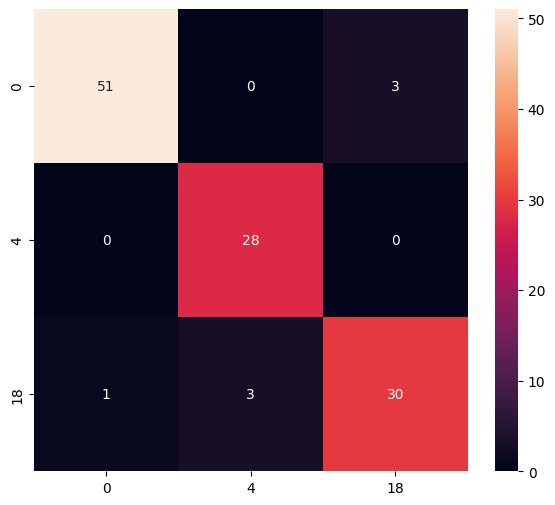

Classification Report
              precision    recall  f1-score   support

           0       0.98      0.94      0.96        54
           4       0.90      1.00      0.95        28
          18       0.91      0.88      0.90        34

    accuracy                           0.94       116
   macro avg       0.93      0.94      0.94       116
weighted avg       0.94      0.94      0.94       116



In [55]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    labels = sorted(list(set(y_true)))
    cmx_data = confusion_matrix(y_true, y_pred, labels=labels)
    
    df_cmx = pd.DataFrame(cmx_data, index=labels, columns=labels)
 
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(df_cmx, annot=True, fmt='g' ,square=False)
    ax.set_ylim(len(set(y_true)), 0)
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

# Convert to model for Tensorflow-Lite

In [56]:
# Save as a model dedicated to inference
model.save(model_save_path, include_optimizer=False)

c:\Users\markl\anaconda3\envs\opencv_env\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [57]:
# Transform model (quantization)
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: C:\Users\markl\AppData\Local\Temp\tmpsw3xkun7\assets


INFO:tensorflow:Assets written to: C:\Users\markl\AppData\Local\Temp\tmpsw3xkun7\assets


7628

# Inference test

In [58]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

In [59]:
# Get I / O tensor
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [60]:
interpreter.set_tensor(input_details[0]['index'], np.array([X_test[0]]))

In [61]:
%%time
# Inference implementation
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])

CPU times: total: 0 ns
Wall time: 0 ns


In [62]:
print(np.squeeze(tflite_results))
print(np.argmax(np.squeeze(tflite_results)))

[9.9993241e-01 1.1931974e-08 2.3703372e-08 2.3212350e-11 3.2585142e-08
 1.3776980e-09 1.2940143e-10 1.5402608e-09 3.1408705e-11 5.9629688e-09
 1.2503085e-10 7.9073317e-11 1.8865721e-10 2.4943067e-10 4.9467830e-10
 1.9081097e-12 1.6360767e-11 5.8621445e-08 6.7494657e-05 1.6287562e-08
 9.6061206e-12 2.4583369e-09 5.2106852e-09 1.6263533e-08 4.7331701e-11
 1.1188615e-11 1.5364154e-11 3.1965286e-10]
0
